# NFL field-goal analysis: accuracy, volume, venue, and weather

This notebook pulls nflverse play-by-play data and studies field-goal makes and attempts by season, kick distance, stadium, surface, roof, temperature, wind, and late-game context.

**Interpretation notes**

- A blocked field goal is an attempt and is treated as not made.
- Attempts affect uncertainty: small-sample percentages can be extreme by chance. Wilson 95% intervals are shown where useful.
- Temperature and wind are analyzed only when recorded and only in outdoor/open venues. Missing indoor weather is not changed to zero.
- These are observational associations, not causal effects. Kicker quality, strategy, altitude, stadium renaming, and kick selection can confound comparisons.
- The default seasons are 2010–2025


## 1. Imports

Using the following dependencies: pandas numpy matplotlib seaborn scipy statsmodels pyarrow requests nfl_data_py


In [2]:
from io import BytesIO
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from IPython.display import display
import nfl_data_py as nfl

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
warnings.filterwarnings('ignore', category=FutureWarning)

SEASONS = list(range(2010, 2026))
SEASON_TYPES = ['REG', 'POST']
MIN_STADIUM_ATTEMPTS = 100
DISTANCE_BINS = [0, 30, 40, 50, 60, np.inf]
DISTANCE_LABELS = ['Under 30', '30–39', '40–49', '50–59', '60+']
PALETTE = dict(zip(DISTANCE_LABELS, sns.color_palette('viridis', len(DISTANCE_LABELS))))

print(f'Seasons requested: {min(SEASONS)}–{max(SEASONS)}')

Seasons requested: 2010–2025


## 2. Load and clean fg data


In [3]:
PBP_COLUMNS = [
    'play_id', 'game_id', 'season', 'season_type', 'week', 'play_type',
    'field_goal_attempt', 'field_goal_result', 'kick_distance',
    'kicker_player_name', 'posteam', 'home_team', 'away_team',
    'stadium', 'roof', 'surface', 'temp', 'wind', 'weather',
    'game_seconds_remaining', 'score_differential', 'qtr'
]

def load_pbp(seasons, columns=PBP_COLUMNS):
    seasons = list(seasons)
    return nfl.import_pbp_data(seasons, columns=columns, downcast=True, cache=False)

pbp = load_pbp(SEASONS)
pbp = pbp.loc[:, [column for column in PBP_COLUMNS if column in pbp.columns]].copy()
print(f'Raw play-by-play rows loaded: {len(pbp):,}')


2010 done.
2011 done.
2012 done.
2013 done.
2014 done.
2015 done.
2016 done.
2017 done.
2018 done.
2019 done.
2020 done.
2021 done.
2022 done.
2023 done.
2024 done.
2025 done.
Downcasting floats.
Raw play-by-play rows loaded: 770,337


In [4]:
def classify_roof(value):
    if pd.isna(value):
        return 'Unknown'
    value = str(value).strip().lower()
    if value in {'dome', 'closed'} or 'indoor' in value:
        return 'Indoor / Closed'
    if value in {'outdoors', 'outdoor', 'open'} or 'outdoor' in value:
        return 'Outdoor / Open'
    return 'Unknown'

def classify_surface(value):
    if pd.isna(value):
        return 'Unknown'
    value = str(value).strip().lower()
    if 'grass' in value:
        return 'Natural Grass'
    if any(token in value for token in ['turf', 'astro', 'synthetic', 'artificial']):
        return 'Artificial Turf'
    return 'Unknown'

fg = pbp.loc[pbp['play_type'].eq('field_goal') | pbp['field_goal_attempt'].eq(1)].copy()
fg['field_goal_result'] = fg['field_goal_result'].astype('string').str.lower()
fg = fg.loc[fg['field_goal_result'].isin(['made', 'missed', 'blocked'])].copy()
fg = fg.dropna(subset=['kick_distance'])
fg = fg.loc[fg['season_type'].isin(SEASON_TYPES)].copy()

for column in ['kick_distance', 'temp', 'wind', 'game_seconds_remaining',
               'score_differential', 'qtr']:
    fg[column] = pd.to_numeric(fg[column], errors='coerce')

fg['Is_Made'] = fg['field_goal_result'].eq('made').astype(int)
fg['Is_Blocked'] = fg['field_goal_result'].eq('blocked').astype(int)
fg['Distance_Bracket'] = pd.cut(fg['kick_distance'], bins=DISTANCE_BINS,
                                labels=DISTANCE_LABELS, right=False, ordered=True)
fg['Roof_Category'] = fg['roof'].map(classify_roof)
fg['Surface_Category'] = fg['surface'].map(classify_surface)
fg['stadium'] = fg['stadium'].fillna('Unknown').astype(str).str.strip()
fg['Late_Game'] = (fg['qtr'].eq(4) & fg['game_seconds_remaining'].le(300)).astype(int)
fg['Artificial'] = fg['Surface_Category'].eq('Artificial Turf').astype(int)
fg['Indoor'] = fg['Roof_Category'].eq('Indoor / Closed').astype(int)
fg['Temperature_Bin'] = pd.cut(
    fg['temp'], [-np.inf, 32, 50, 70, 85, np.inf],
    labels=['≤32°F', '33–50°F', '51–70°F', '71–85°F', '86°F+'])
fg['Wind_Bin'] = pd.cut(
    fg['wind'], [-0.01, 5, 10, 15, 20, np.inf],
    labels=['0–4 mph', '5–9 mph', '10–14 mph', '15–19 mph', '20+ mph'],
    right=False)

print(f'Valid field-goal attempts: {len(fg):,}')
print(f'Loaded seasons: {int(fg.season.min())}–{int(fg.season.max())}')
display(fg.head())


Valid field-goal attempts: 16,927
Loaded seasons: 2010–2025


,play_id,game_id,season,season_type,week,play_type,field_goal_attempt,field_goal_result,kick_distance,kicker_player_name,posteam,home_team,away_team,stadium,roof,surface,temp,wind,weather,game_seconds_remaining,score_differential,qtr,Is_Made,Is_Blocked,Distance_Bracket,Roof_Category,Surface_Category,Late_Game,Artificial,Indoor,Temperature_Bin,Wind_Bin
14,350.000,2010_01_ARI_STL,2010,REG,1,field_goal,1.000,blocked,34.000,Josh.Brown,LA,LA,ARI,Edward Jones Dome,dome,astroplay,NaN,NaN,"Temp: ° F, Wind: mph","3,281.000",0.000,1.000,0,1,30–39,Indoor / Closed,Artificial Turf,0,1,1,NaN,NaN
42,"1,018.000",2010_01_ARI_STL,2010,REG,1,field_goal,1.000,made,22.000,J.Feely,ARI,LA,ARI,Edward Jones Dome,dome,astroplay,NaN,NaN,"Temp: ° F, Wind: mph","2,637.000",0.000,2.000,1,0,Under 30,Indoor / Closed,Artificial Turf,0,1,1,NaN,NaN
66,"1,602.000",2010_01_ARI_STL,2010,REG,1,field_goal,1.000,made,46.000,Josh.Brown,LA,LA,ARI,Edward Jones Dome,dome,astroplay,NaN,NaN,"Temp: ° F, Wind: mph","2,133.000",-3.000,2.000,1,0,40–49,Indoor / Closed,Artificial Turf,0,1,1,NaN,NaN
117,"2,826.000",2010_01_ARI_STL,2010,REG,1,field_goal,1.000,made,25.000,Josh.Brown,LA,LA,ARI,Edward Jones Dome,dome,astroplay,NaN,NaN,"Temp: ° F, Wind: mph","1,412.000",0.000,3.000,1,0,Under 30,Indoor / Closed,Artificial Turf,0,1,1,NaN,NaN
209,280.000,2010_01_ATL_PIT,2010,REG,1,field_goal,1.000,made,52.000,J.Reed,PIT,PIT,ATL,Acrisure Stadium,outdoors,grass,65.000,9.000,"Cloudy Temp: 65° F, Humidity: 67%, Wind: From ...","3,177.000",0.000,1.000,1,0,50–59,Outdoor / Open,Natural Grass,0,0,0,51–70°F,5–9 mph


### Examining Data


In [5]:
outcome_audit = fg['field_goal_result'].value_counts(dropna=False).rename_axis('Result').to_frame('Attempts')
outcome_audit['Percent'] = 100 * outcome_audit['Attempts'] / len(fg)
weather_audit = fg.groupby('Roof_Category', observed=True).agg(
    Attempts=('Is_Made', 'size'), Temperature_Available=('temp', 'count'),
    Wind_Available=('wind', 'count'))
weather_audit['Temperature_Coverage_Pct'] = 100 * weather_audit['Temperature_Available'] / weather_audit['Attempts']
weather_audit['Wind_Coverage_Pct'] = 100 * weather_audit['Wind_Available'] / weather_audit['Attempts']
display(outcome_audit)
display(weather_audit)


,Attempts,Percent
Result,,
made,14301,84.486
missed,2292,13.540
blocked,334,1.973


,Attempts,Temperature_Available,Wind_Available,Temperature_Coverage_Pct,Wind_Coverage_Pct
Roof_Category,,,,,
Indoor / Closed,4815,4,4,0.083,0.083
Outdoor / Open,12112,11316,11316,93.428,93.428


## 3. Reusable summaries and uncertainty

Success rate is makes divided by attempts. Wilson intervals behave better than simple normal intervals for small samples or percentages near 0%/100%.


In [6]:
def add_wilson_interval(frame, z=1.96):
    frame = frame.copy()
    n = frame['Attempts'].astype(float)
    p = frame['Makes'] / n
    denominator = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denominator
    half = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denominator
    frame['Success_Rate'] = p
    frame['CI_Low'] = center - half
    frame['CI_High'] = center + half
    return frame

def summarize_rates(data, groups):
    if isinstance(groups, str):
        groups = [groups]
    result = data.groupby(groups, observed=True).agg(
        Attempts=('Is_Made', 'size'), Makes=('Is_Made', 'sum'),
        Average_Distance=('kick_distance', 'mean')).reset_index()
    return add_wilson_interval(result)

overall = summarize_rates(fg.assign(All='All attempts'), 'All')
overall_display = overall[['Attempts', 'Makes', 'Success_Rate', 'Average_Distance']].copy()
overall_display['Success_Rate'] *= 100
display(overall_display.rename(columns={'Success_Rate': 'Success_Rate_Pct'}))


,Attempts,Makes,Success_Rate_Pct,Average_Distance
0,16927,14301,84.486,38.348


## 4. Accuracy and attempts by season and distance

Aligned rate and volume panels prevent a rate trend from being read without its number and mix of attempts.


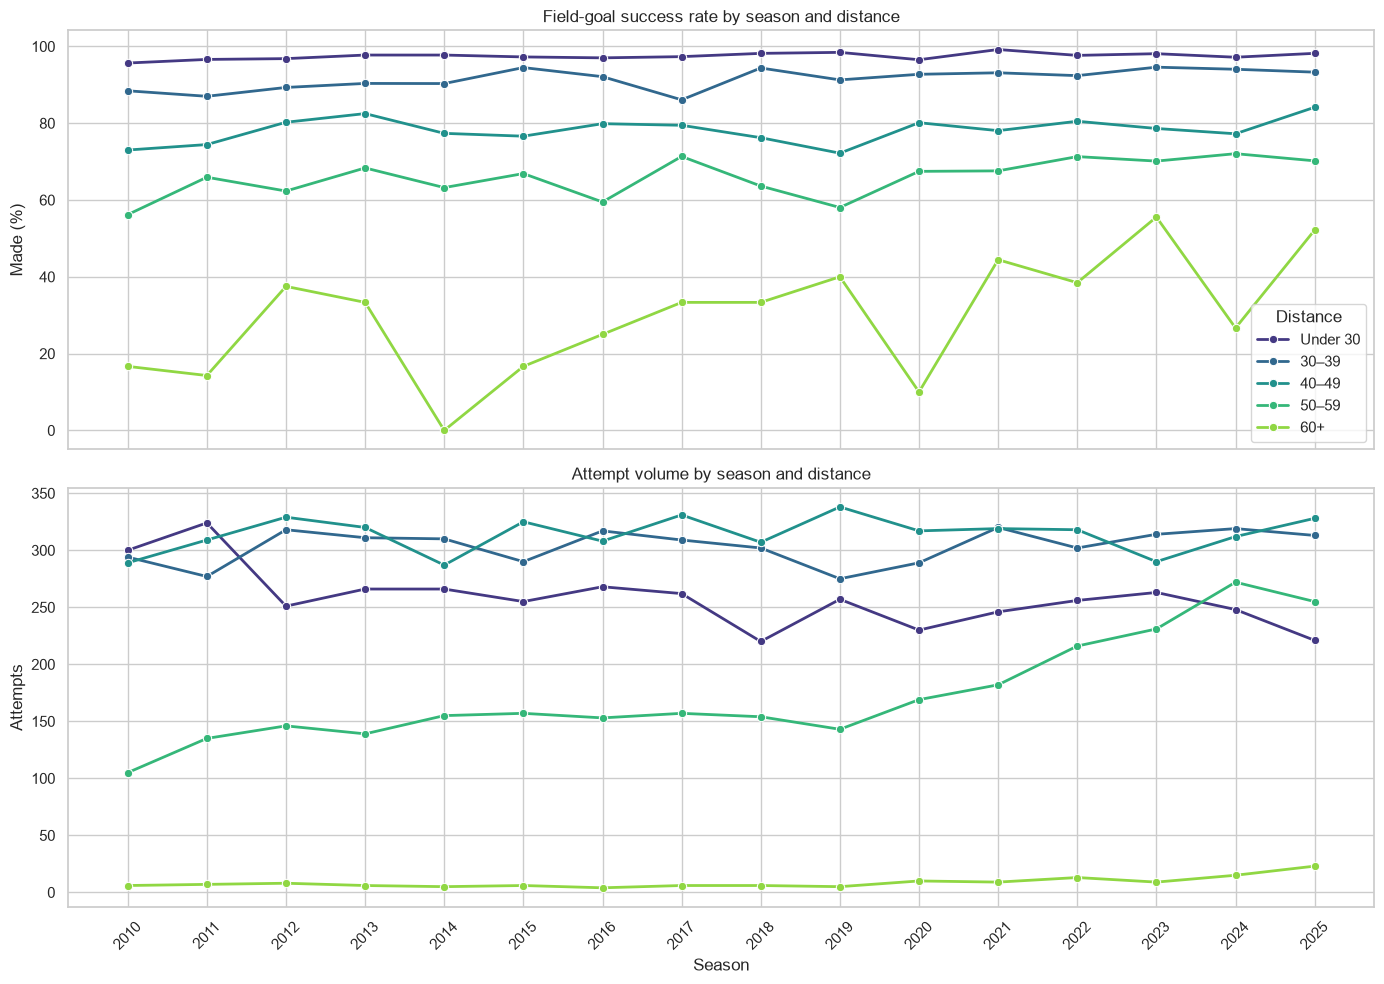

,season,Distance_Bracket,Attempts,Makes,Success_Pct,Average_Distance
65,2023,Under 30,263,258,98.099,25.202
66,2023,30–39,314,297,94.586,34.666
67,2023,40–49,290,228,78.621,44.372
68,2023,50–59,231,162,70.130,53.251
69,2023,60+,9,5,55.556,61.000
70,2024,Under 30,248,241,97.177,25.202
71,2024,30–39,319,300,94.044,34.376
72,2024,40–49,312,241,77.244,44.603
73,2024,50–59,272,196,72.059,53.298
74,2024,60+,15,4,26.667,62.800


In [7]:
season_distance = summarize_rates(fg, ['season', 'Distance_Bracket'])
season_distance['Success_Pct'] = 100 * season_distance['Success_Rate']
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
sns.lineplot(data=season_distance, x='season', y='Success_Pct',
             hue='Distance_Bracket', hue_order=DISTANCE_LABELS,
             palette=PALETTE, marker='o', linewidth=2, ax=axes[0])
axes[0].set(title='Field-goal success rate by season and distance',
            ylabel='Made (%)', xlabel='')
axes[0].legend(title='Distance')
sns.lineplot(data=season_distance, x='season', y='Attempts',
             hue='Distance_Bracket', hue_order=DISTANCE_LABELS,
             palette=PALETTE, marker='o', linewidth=2, ax=axes[1], legend=False)
axes[1].set(title='Attempt volume by season and distance',
            ylabel='Attempts', xlabel='Season')
axes[1].set_xticks(sorted(season_distance['season'].unique()))
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
display(season_distance[['season', 'Distance_Bracket', 'Attempts', 'Makes',
                         'Success_Pct', 'Average_Distance']].tail(15))


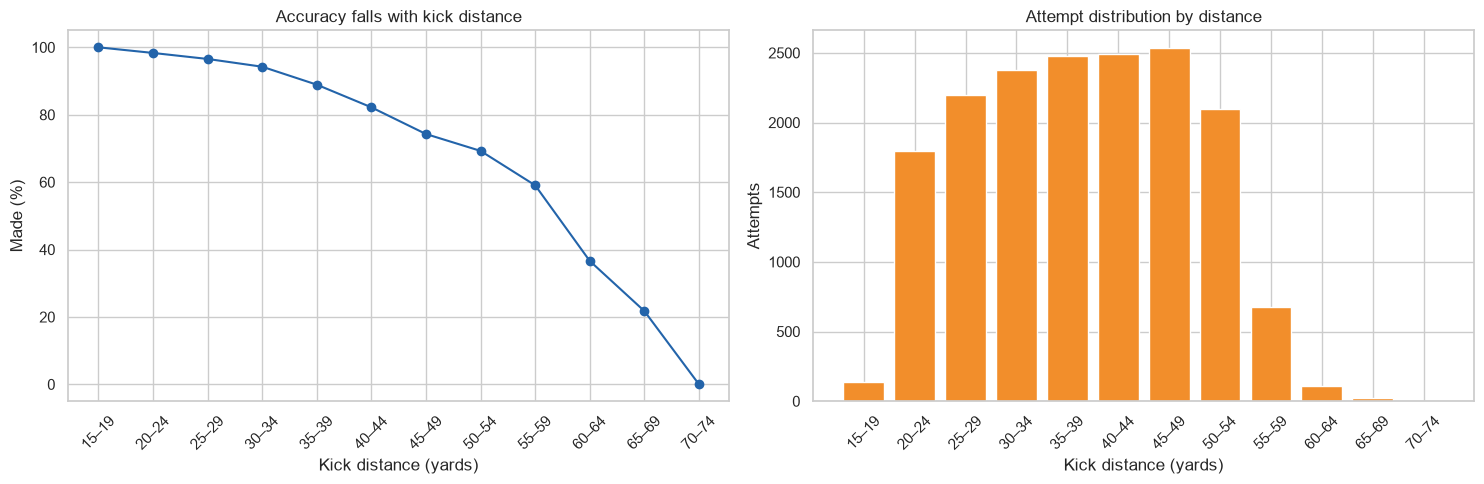

In [8]:
# Five-yard bins show both the continuous distance relationship and attempt mix.
distance_edges = list(range(15, 76, 5)) + [np.inf]
distance_labels_5 = [f'{x}–{x + 4}' for x in range(15, 75, 5)] + ['75+']
fg['Distance_5yd'] = pd.cut(fg['kick_distance'], bins=distance_edges,
                            labels=distance_labels_5, right=False, include_lowest=True)
distance_summary = summarize_rates(fg.dropna(subset=['Distance_5yd']), 'Distance_5yd')
distance_summary['Success_Pct'] = 100 * distance_summary['Success_Rate']
x = np.arange(len(distance_summary))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(x, distance_summary['Success_Pct'], marker='o', color='#2364aa')
axes[0].set(title='Accuracy falls with kick distance', ylabel='Made (%)',
            xlabel='Kick distance (yards)')
axes[0].set_xticks(x, distance_summary['Distance_5yd'].astype(str), rotation=45)
axes[1].bar(x, distance_summary['Attempts'], color='#f28e2b')
axes[1].set(title='Attempt distribution by distance', ylabel='Attempts',
            xlabel='Kick distance (yards)')
axes[1].set_xticks(x, distance_summary['Distance_5yd'].astype(str), rotation=45)
plt.tight_layout(); plt.show()


## 5. Surface and roof comparisons

Rates and volumes are split by distance so a category is not rewarded merely for receiving more short attempts. Unknown categories are excluded here but remain visible in the audit.


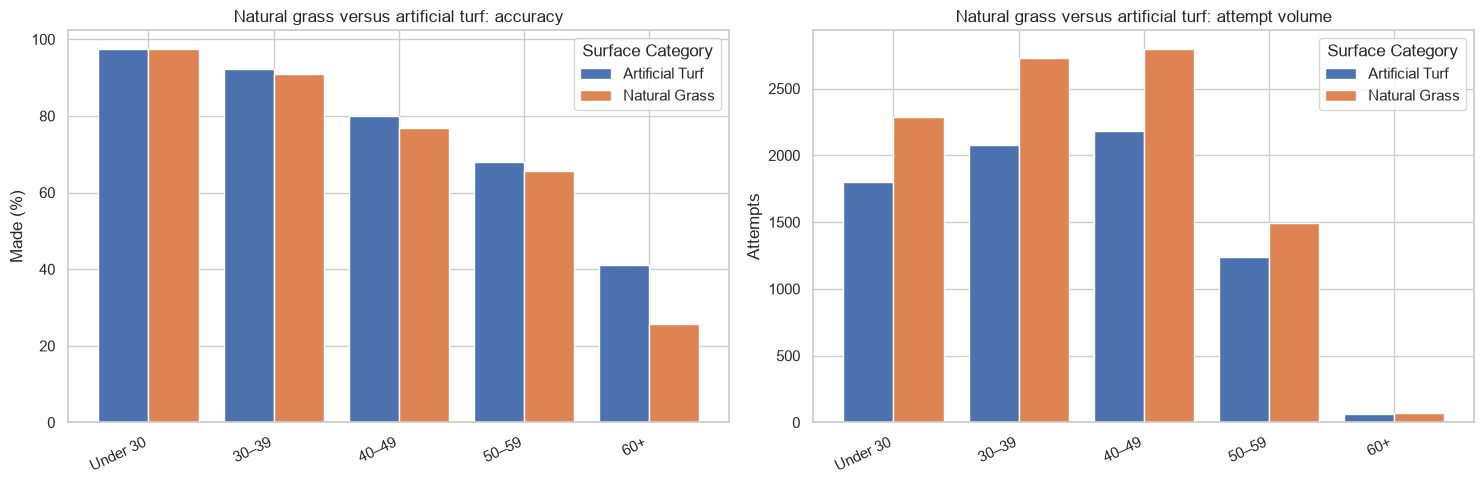

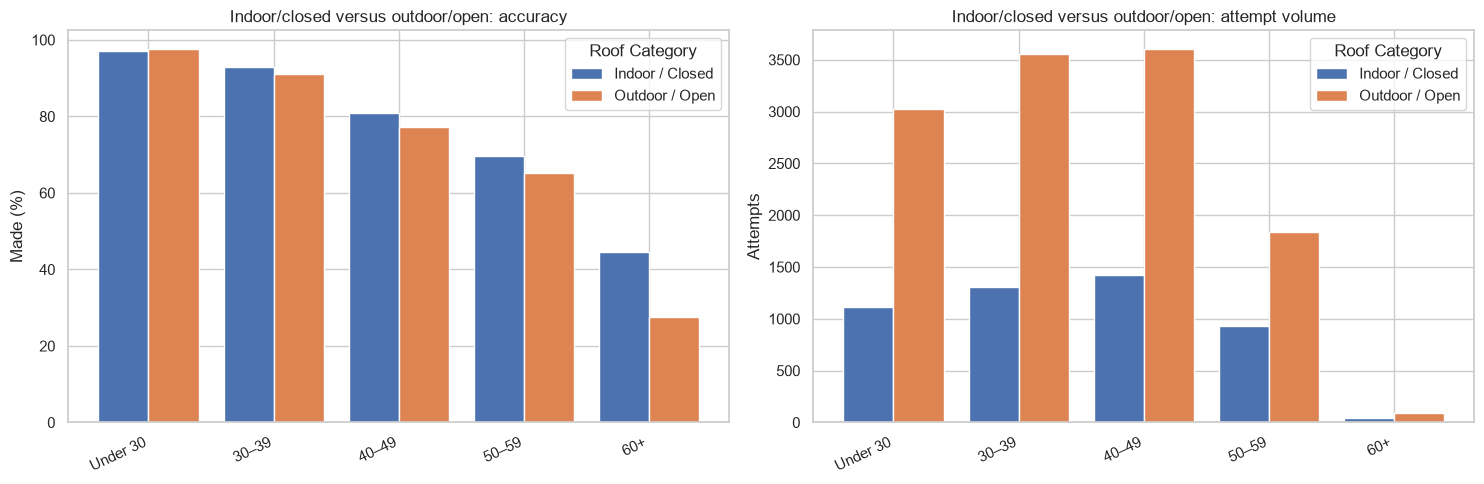

,Surface_Category,Distance_Bracket,Attempts,Makes,Success_Pct
0,Artificial Turf,Under 30,1802,1755,97.392
1,Artificial Turf,30–39,2078,1914,92.108
2,Artificial Turf,40–49,2183,1743,79.844
3,Artificial Turf,50–59,1240,844,68.065
4,Artificial Turf,60+,61,25,40.984
5,Natural Grass,Under 30,2289,2230,97.422
6,Natural Grass,30–39,2726,2481,91.012
7,Natural Grass,40–49,2795,2147,76.816
8,Natural Grass,50–59,1494,982,65.730
9,Natural Grass,60+,74,19,25.676


,Roof_Category,Distance_Bracket,Attempts,Makes,Success_Pct
0,Indoor / Closed,Under 30,1112,1079,97.032
1,Indoor / Closed,30–39,1303,1210,92.863
2,Indoor / Closed,40–49,1424,1153,80.969
3,Indoor / Closed,50–59,929,648,69.752
4,Indoor / Closed,60+,47,21,44.681
5,Outdoor / Open,Under 30,3021,2948,97.584
6,Outdoor / Open,30–39,3557,3238,91.032
7,Outdoor / Open,40–49,3603,2778,77.102
8,Outdoor / Open,50–59,1840,1201,65.272
9,Outdoor / Open,60+,91,25,27.473


In [9]:
def plot_category_rate_and_volume(data, category, title):
    summary = summarize_rates(data, [category, 'Distance_Bracket'])
    summary['Success_Pct'] = 100 * summary['Success_Rate']
    categories = list(summary[category].dropna().unique())
    x = np.arange(len(DISTANCE_LABELS))
    width = .8 / max(len(categories), 1)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
    for i, value in enumerate(categories):
        part = summary.loc[summary[category].eq(value)].set_index('Distance_Bracket').reindex(DISTANCE_LABELS)
        position = x - .4 + width / 2 + i * width
        axes[0].bar(position, part['Success_Pct'], width, label=value)
        axes[1].bar(position, part['Attempts'], width, label=value)
    for ax in axes:
        ax.set_xticks(x, DISTANCE_LABELS, rotation=25, ha='right')
        ax.legend(title=category.replace('_', ' '))
    axes[0].set(title=f'{title}: accuracy', ylabel='Made (%)')
    axes[1].set(title=f'{title}: attempt volume', ylabel='Attempts')
    plt.tight_layout(); plt.show()
    return summary

surface_summary = plot_category_rate_and_volume(
    fg.loc[fg['Surface_Category'].ne('Unknown')], 'Surface_Category',
    'Natural grass versus artificial turf')
roof_summary = plot_category_rate_and_volume(
    fg.loc[fg['Roof_Category'].ne('Unknown')], 'Roof_Category',
    'Indoor/closed versus outdoor/open')
display(surface_summary[['Surface_Category', 'Distance_Bracket', 'Attempts', 'Makes', 'Success_Pct']])
display(roof_summary[['Roof_Category', 'Distance_Bracket', 'Attempts', 'Makes', 'Success_Pct']])


## 6. Temperature and wind exploration

Weather is limited to outdoor/open venues with valid measurements. A point is retained only when its distance/weather cell has at least 20 attempts; attempt panels expose thin or uneven samples.


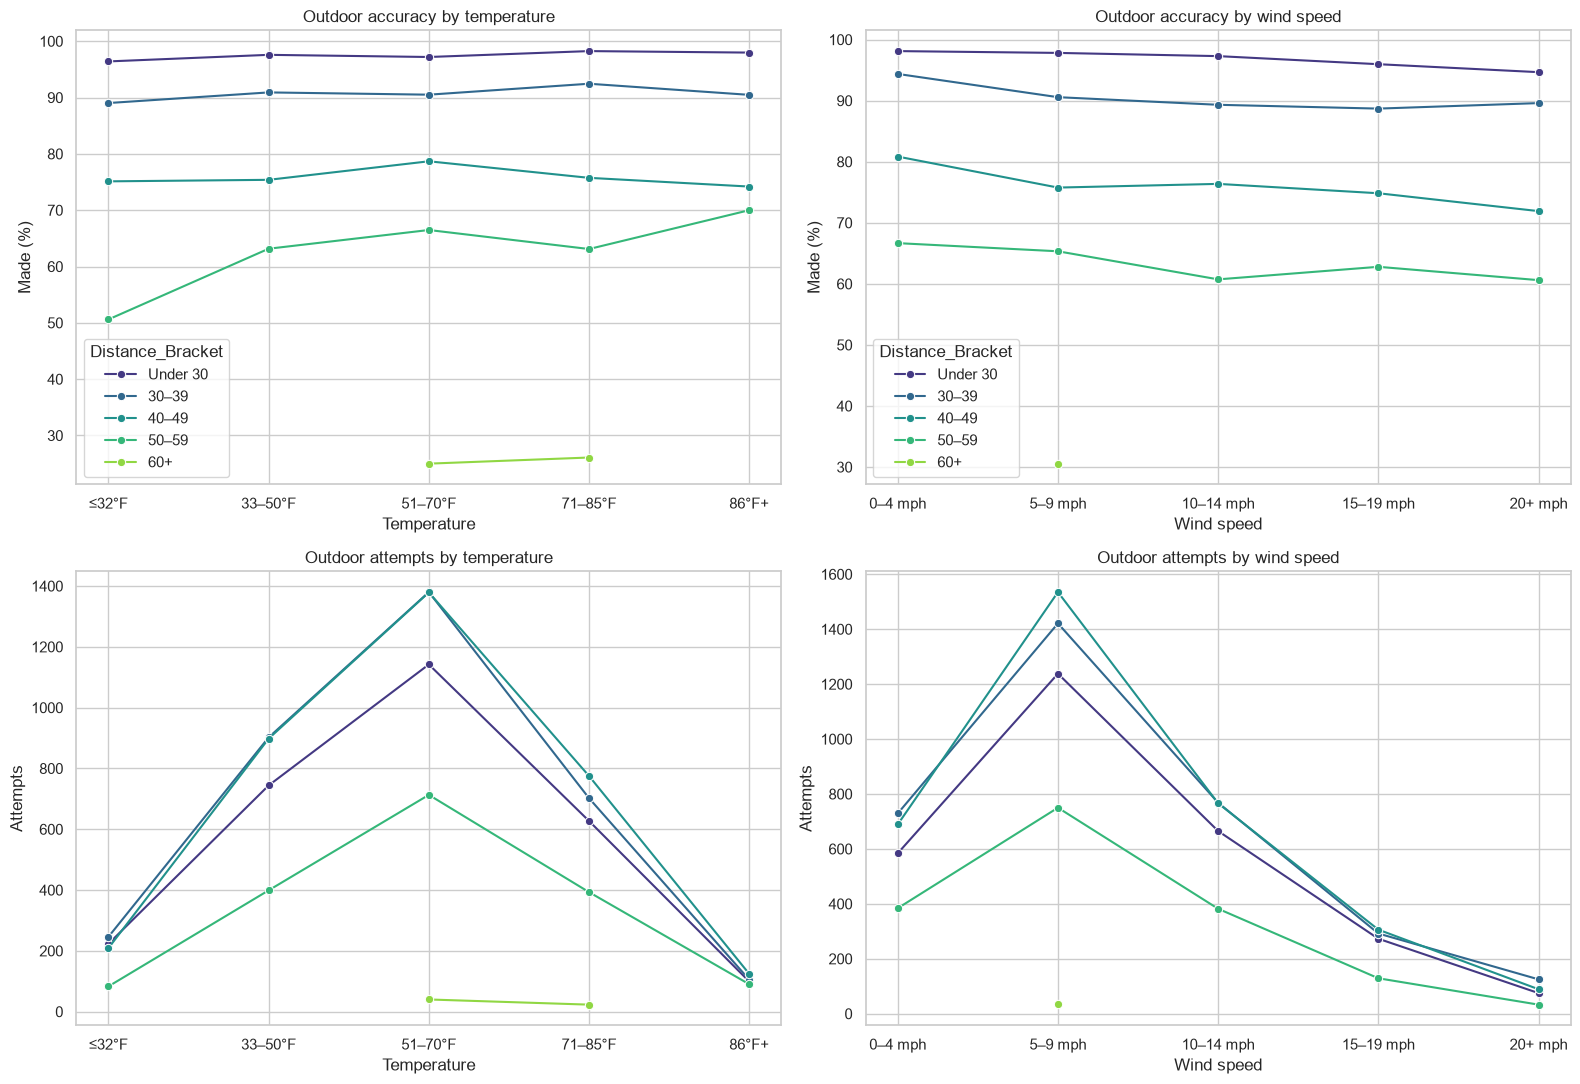

Outdoor attempts with both temperature and wind: 11,313


,Temperature_Bin,Distance_Bracket,Attempts,Success_Pct
0,≤32°F,Under 30,223,96.413
1,≤32°F,30–39,246,89.024
2,≤32°F,40–49,209,75.120
3,≤32°F,50–59,83,50.602
5,33–50°F,Under 30,744,97.581
6,33–50°F,30–39,902,90.909
7,33–50°F,40–49,898,75.390
8,33–50°F,50–59,399,63.158
10,51–70°F,Under 30,1142,97.198
11,51–70°F,30–39,1380,90.507


,Wind_Bin,Distance_Bracket,Attempts,Success_Pct
0,0–4 mph,Under 30,584,98.116
1,0–4 mph,30–39,729,94.376
2,0–4 mph,40–49,689,80.842
3,0–4 mph,50–59,384,66.667
5,5–9 mph,Under 30,1238,97.819
6,5–9 mph,30–39,1421,90.570
7,5–9 mph,40–49,1535,75.765
8,5–9 mph,50–59,750,65.333
9,5–9 mph,60+,36,30.556
10,10–14 mph,Under 30,665,97.293


In [10]:
outdoor = fg.loc[fg['Roof_Category'].eq('Outdoor / Open')
                 & fg['temp'].between(-30, 130)
                 & fg['wind'].between(0, 60)].copy()
temp_summary = summarize_rates(outdoor.dropna(subset=['Temperature_Bin']),
                               ['Temperature_Bin', 'Distance_Bracket'])
wind_summary = summarize_rates(outdoor.dropna(subset=['Wind_Bin']),
                               ['Wind_Bin', 'Distance_Bracket'])
temp_summary = temp_summary.loc[temp_summary['Attempts'].ge(20)].copy()
wind_summary = wind_summary.loc[wind_summary['Attempts'].ge(20)].copy()
temp_summary['Success_Pct'] = 100 * temp_summary['Success_Rate']
wind_summary['Success_Pct'] = 100 * wind_summary['Success_Rate']

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
sns.lineplot(data=temp_summary, x='Temperature_Bin', y='Success_Pct',
    hue='Distance_Bracket', hue_order=DISTANCE_LABELS, palette=PALETTE,
    marker='o', ax=axes[0, 0])
axes[0, 0].set(title='Outdoor accuracy by temperature', ylabel='Made (%)', xlabel='Temperature')
sns.lineplot(data=temp_summary, x='Temperature_Bin', y='Attempts',
    hue='Distance_Bracket', hue_order=DISTANCE_LABELS, palette=PALETTE,
    marker='o', legend=False, ax=axes[1, 0])
axes[1, 0].set(title='Outdoor attempts by temperature', ylabel='Attempts', xlabel='Temperature')
sns.lineplot(data=wind_summary, x='Wind_Bin', y='Success_Pct',
    hue='Distance_Bracket', hue_order=DISTANCE_LABELS, palette=PALETTE,
    marker='o', ax=axes[0, 1])
axes[0, 1].set(title='Outdoor accuracy by wind speed', ylabel='Made (%)', xlabel='Wind speed')
sns.lineplot(data=wind_summary, x='Wind_Bin', y='Attempts',
    hue='Distance_Bracket', hue_order=DISTANCE_LABELS, palette=PALETTE,
    marker='o', legend=False, ax=axes[1, 1])
axes[1, 1].set(title='Outdoor attempts by wind speed', ylabel='Attempts', xlabel='Wind speed')
plt.tight_layout(); plt.show()
print(f'Outdoor attempts with both temperature and wind: {len(outdoor):,}')
display(temp_summary[['Temperature_Bin', 'Distance_Bracket', 'Attempts', 'Success_Pct']])
display(wind_summary[['Wind_Bin', 'Distance_Bracket', 'Attempts', 'Success_Pct']])


## 7. Adjusted significance tests

Two logistic regressions test whether associations remain after adjustment. The venue model uses distance (including curvature), surface, roof, late-game status, and season effects. The outdoor-weather model uses distance, temperature, wind, surface, late-game status, and season effects among outdoor attempts with valid weather. Standard errors are clustered by game because attempts in one game share venue and weather conditions. Odds ratios above 1 mean higher odds of a make; significance is p < 0.05.


In [11]:
def prepare_model_data(data):
    data = data.copy()
    data['Distance10'] = data['kick_distance'] / 10
    data['Distance10_sq'] = data['Distance10'] ** 2
    data['Temp10'] = (data['temp'] - 60) / 10
    data['Wind5'] = data['wind'] / 5
    return data

def fit_clustered_logit(formula, data):
    return smf.logit(formula, data=data).fit(
        disp=False, maxiter=200, cov_type='cluster',
        cov_kwds={'groups': data['game_id']})

def odds_ratio_table(result, terms):
    confidence = result.conf_int()
    table = pd.DataFrame({'Odds_Ratio': np.exp(result.params),
                          'CI_Low': np.exp(confidence[0]),
                          'CI_High': np.exp(confidence[1]),
                          'P_Value': result.pvalues}).reindex(terms).dropna(how='all')
    table['Significant_0.05'] = table['P_Value'].lt(.05)
    return table

venue_data = fg.loc[fg['Surface_Category'].ne('Unknown')
                    & fg['Roof_Category'].ne('Unknown')
                    & fg['kick_distance'].between(15, 75)].dropna(
                        subset=['game_id', 'season', 'Late_Game']).copy()
venue_data = prepare_model_data(venue_data)
venue_model = fit_clustered_logit(
    'Is_Made ~ Distance10 + Distance10_sq + Artificial + Indoor + Late_Game + C(season)',
    venue_data)
venue_terms = ['Distance10', 'Distance10_sq', 'Artificial', 'Indoor', 'Late_Game']
venue_or = odds_ratio_table(venue_model, venue_terms)

weather_data = outdoor.loc[outdoor['Surface_Category'].ne('Unknown')
                           & outdoor['kick_distance'].between(15, 75)].dropna(
                               subset=['game_id', 'season', 'temp', 'wind', 'Late_Game']).copy()
weather_data = prepare_model_data(weather_data)
weather_model = fit_clustered_logit(
    'Is_Made ~ Distance10 + Distance10_sq + Temp10 + Wind5 + Artificial + Late_Game + C(season)',
    weather_data)
weather_terms = ['Distance10', 'Distance10_sq', 'Temp10', 'Wind5', 'Artificial', 'Late_Game']
weather_or = odds_ratio_table(weather_model, weather_terms)

print(f'Venue model: {len(venue_data):,} attempts, {venue_data.game_id.nunique():,} games')
display(venue_or)
print(f'Outdoor weather model: {len(weather_data):,} attempts, {weather_data.game_id.nunique():,} games')
display(weather_or)


Venue model: 16,742 attempts, 4,261 games


,Odds_Ratio,CI_Low,CI_High,P_Value,Significant_0.05
Distance10,0.154,0.103,0.231,0.000,True
Distance10_sq,1.102,1.051,1.156,0.000,True
Artificial,1.070,0.963,1.189,0.207,False
Indoor,1.174,1.042,1.324,0.009,True
Late_Game,0.943,0.825,1.079,0.395,False


Outdoor weather model: 11,313 attempts, 2,919 games


,Odds_Ratio,CI_Low,CI_High,P_Value,Significant_0.05
Distance10,0.165,0.101,0.268,0.000,True
Distance10_sq,1.088,1.027,1.152,0.004,True
Temp10,1.039,1.005,1.073,0.023,True
Wind5,0.890,0.846,0.937,0.000,True
Artificial,1.034,0.913,1.172,0.598,False
Late_Game,0.965,0.819,1.138,0.672,False


In [12]:
EFFECT_LABELS = {
    'Artificial': 'artificial turf versus natural grass',
    'Indoor': 'indoor/closed versus outdoor/open',
    'Late_Game': 'final five minutes of the fourth quarter',
    'Temp10': 'a 10°F increase in outdoor temperature',
    'Wind5': 'a 5 mph increase in outdoor wind'}

def explain_effects(table, terms):
    for term in terms:
        row = table.loc[term]
        label = EFFECT_LABELS[term]
        direction = 'higher' if row['Odds_Ratio'] > 1 else 'lower'
        if row['P_Value'] < .05:
            print(f'• {label}: significant {direction} odds of a make '
                  f'(OR {row.Odds_Ratio:.3f}, 95% CI {row.CI_Low:.3f}–{row.CI_High:.3f}, '
                  f'p={row.P_Value:.3g}).')
        else:
            print(f'• {label}: not statistically significant after adjustment '
                  f'(OR {row.Odds_Ratio:.3f}, 95% CI {row.CI_Low:.3f}–{row.CI_High:.3f}, '
                  f'p={row.P_Value:.3g}).')

print('Adjusted venue/context effects')
explain_effects(venue_or, ['Artificial', 'Indoor', 'Late_Game'])
print('\nAdjusted outdoor-weather effects')
explain_effects(weather_or, ['Temp10', 'Wind5', 'Artificial', 'Late_Game'])
print('\nP-values describe associations in this sample; they do not establish causation.')


Adjusted venue/context effects
• artificial turf versus natural grass: not statistically significant after adjustment (OR 1.070, 95% CI 0.963–1.189, p=0.207).
• indoor/closed versus outdoor/open: significant higher odds of a make (OR 1.174, 95% CI 1.042–1.324, p=0.00854).
• final five minutes of the fourth quarter: not statistically significant after adjustment (OR 0.943, 95% CI 0.825–1.079, p=0.395).

Adjusted outdoor-weather effects
• a 10°F increase in outdoor temperature: significant higher odds of a make (OR 1.039, 95% CI 1.005–1.073, p=0.0233).
• a 5 mph increase in outdoor wind: significant lower odds of a make (OR 0.890, 95% CI 0.846–0.937, p=8.88e-06).
• artificial turf versus natural grass: not statistically significant after adjustment (OR 1.034, 95% CI 0.913–1.172, p=0.598).
• final five minutes of the fourth quarter: not statistically significant after adjustment (OR 0.965, 95% CI 0.819–1.138, p=0.672).

P-values describe associations in this sample; they do not establish 